# Prepare MISR data

This notebook extracts radiometric and geometric information from the MISR data files.

Red BRF is taken from the MISR Georectified Radiance Product `MISR_AM1_GRP_ELLIPSOID_GM_Pxxx_Oxxxxxx_CC_F03_0024.hdf`.

Solar and viewing angles are taken from the geometric parameters ancillary dataset `MISR_AM1_GP_GMP_Pxxx_Oxxxxxx_F03_0013.hdf`.

In [1]:
# conda env 'misr'
import MisrToolkit as mtk
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
import sys

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
from src.MISR import hdf2xr, grp2xr

In [4]:
## Set data path
misr_data_dir = PROJECT_ROOT / 'data' / 'raw' / 'MISR'

## Specify MISR parameters
path = 117
orbit = 105254
cameras = ['DF', 'CF', 'BF', 'AF', 'AN', 'AA', 'BA', 'CA', 'DA']

## Define geographic region
center_lat = 19.266267063099104
center_lon = 119.72428415176724
region = mtk.MtkRegion(center_lat, center_lon, 8.8*3, 8.8*3, "km")

## Load MISR red band images
imagery = grp2xr(misr_data_dir, path, orbit, cameras, region)
imagery.to_netcdf(PROJECT_ROOT / 'data' / 'interim' / f'MISR_RAD_O{orbit:06}_{imagery.regionID}.nc')

## Load geometric parameters
gmp_file = misr_data_dir / f'MISR_AM1_GP_GMP_P{path}_O{orbit}_F03_0013.hdf'
field_list_solar = ['SolarZenith', 'SolarAzimuth']
field_list_vza = [f'{c.lower().capitalize()}Zenith' for c in cameras]
field_list_vaa = [f'{c.lower().capitalize()}Azimuth' for c in cameras]
field_list = field_list_solar + field_list_vza + field_list_vaa
gmp = hdf2xr(gmp_file, 'GeometricParameters', field_list, region)
gmp.to_netcdf(PROJECT_ROOT / 'data' / 'interim' / f'MISR_GEO_O{orbit:06}_{gmp.regionID}.nc')

## Load CTH
tc_cloud_file = misr_data_dir / f'MISR_AM1_TC_CLOUD_P{path:03d}_O{orbit:06d}_F01_0001.hdf'
cth = hdf2xr(tc_cloud_file, 'Stereo_1.1_km', ['CloudTopHeight', 'StereoDerivedCloudMask'], region)
cth.to_netcdf(PROJECT_ROOT / 'data' / 'interim' / f'MISR_CTH_O{orbit:06}_{cth.regionID}.nc')

## Load CMV
cmv = hdf2xr(tc_cloud_file, 'Motion_17.6_km', ['CloudTopHeightOfMotion', 'CloudMotionNorthward', 'CloudMotionEastward'], region)
cmv.to_netcdf(PROJECT_ROOT / 'data' / 'interim' / f'MISR_CMV_O{orbit:06}_{cmv.regionID}.nc')


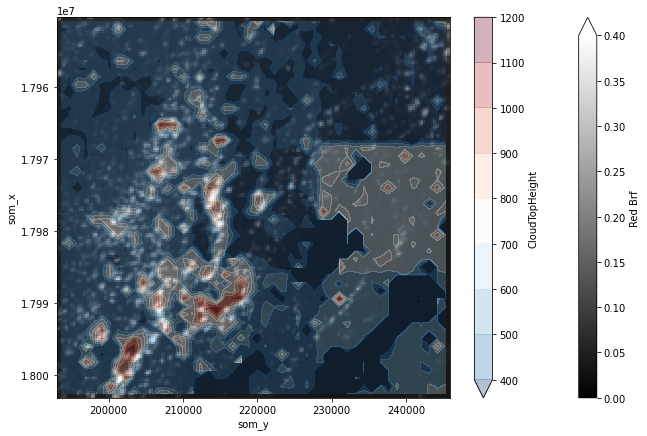

In [6]:
image_kwargs = {
    'cmap': 'gray',
    'vmin': 0.0,
    'vmax': 0.4
}

cth_kwargs = {
    'levels': np.arange(400, 1250, 100),
    # 'levels': np.array([399.5, 400.5]),
    'add_colorbar': True,
    'add_labels': True,
    'alpha': 0.3
}

cm_kwargs = {
    'add_colorbar': True,
    'levels': np.array([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5]),
    'alpha': 0.3
}

f, ax = plt.subplots(1, 1, figsize=(11,7))
imagery.sel(camera='BF').brf.plot(ax=ax, **image_kwargs)
cth.CloudTopHeight.plot.contourf(ax=ax, **cth_kwargs)
# cth.StereoDerivedCloudMask.plot.contourf(ax=ax, **cm_kwargs)
ax.invert_yaxis()

In [ ]:
image_kwargs = {
    'cmap': 'gray',
    'vmin': 0.0,
    'vmax': 0.4,
    'add_colorbar': False
}

cth_kwargs = {
    'levels': np.arange(400, 1250, 100),
    # 'levels': np.array([399.5, 400.5]),
    'add_colorbar': False,
    'add_labels': False,
    'alpha': 0.3
}

f, ax = plt.subplots(3, 3, figsize=(15, 15))
ax = ax.flatten()
for i in range(9):
    imagery.isel(camera=i).brf.plot(ax=ax[i], **image_kwargs)
    cth.CloudTopHeight.plot.contourf(ax=ax[i], **cth_kwargs)
    ax[i].invert_yaxis()
plt.tight_layout()

In [5]:
cmv

<xarray.Dataset>
Dimensions:                 (som_x: 3, som_y: 3)
Coordinates:
  * som_x                   (som_x) float64 1.796e+07 1.798e+07 1.799e+07
  * som_y                   (som_y) float64 2.018e+05 2.194e+05 2.370e+05
Data variables:
    lat                     (som_x, som_y) float64 19.44 19.42 ... 19.11 19.09
    lon                     (som_x, som_y) float64 119.6 119.7 ... 119.7 119.9
    gamma                   (som_x, som_y) float64 1.654 1.655 ... 1.655 1.656
    CloudTopHeightOfMotion  (som_x, som_y) float32 521.1 531.3 ... 591.1 513.6
    CloudMotionNorthward    (som_x, som_y) float32 1.202 1.466 ... 1.004 0.09489
    CloudMotionEastward     (som_x, som_y) float32 1.594 1.463 ... -0.07763
Attributes:
    path:         117
    orbit:        105254
    block_range:  (75, 75)
    resolution:   17600
    regionID:     P117_R17600_X17959150_17994350_Y0201850_0237050